# 5. Fine-Tune the System: tuning, ensembles and the final test-set evaluation

**Owner:** Tasnim Hassan · INSY 674 Fall 2026 · Olist late-delivery project

This notebook covers README sections **5.1 to 5.4** and the rubric row *Fine-Tune the System*:

| Rubric "Excellent" item | Where in this notebook |
|---|---|
| Tunes shortlisted models with CV | 5.1 (5-fold time-series CV, `refit="pr_auc"`) |
| Justified search method | 5.1.1 |
| Data-preparation choices treated as hyperparameters | 5.1.1, 5.1.4 (encoding), 5.1.6 (dropping `purchase_month`) |
| Tries ensembles | 5.2 |
| Evaluates on the test set (once) | 5.3, the only cell that reads the test labels |
| Performance vs baseline | 5.3 (B0, B1, plus a paired bootstrap) |
| Explains the final model and its limitations | 5.4 |

**Inputs from teammates.** Preprocessing pipeline from Mia (section 3.4), shortlist from Fidan (section 4.5: Logistic Regression, Random Forest, HistGradientBoosting), error overlap from Jingyu (section 4.3.4), which showed the three models catch partly different late orders and so motivated the ensemble test.

**Ground rules (DECISIONS.md).** Training period only until 5.3 (D6). All CV uses the shared `cv_splitter()` and `scorers()` from `src/evaluation.py` (D7, D8). Selection metric is PR-AUC (CONVENTIONS §5). Only approval-time features (D5).

**Runtime:** about 95 minutes on a 2-core machine (93.9 minutes on the last full run) (the three searches are 450 model fits). Every random step uses `config.RANDOM_STATE`, so a rerun reproduces these numbers.

## 0. Setup

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

# Make `src` importable whether the notebook runs from notebooks/ or the repo root.
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config
from src.evaluation import cv_splitter, scorers, recall_at_budget

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (HistGradientBoostingClassifier, RandomForestClassifier,
                              VotingClassifier)
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler)

RS = config.RANDOM_STATE  # 42, shared seed
FIG_DIR = ROOT / "reports" / "figures" / "fine_tune"
OUT_DIR = ROOT / "reports" / "outputs"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn infrequent-category notices
NOTEBOOK_START = time.time()

### 0.1 Data and split

Same table, same split and same 20 features as Mia's pipeline and Fidan's benchmark, so every number here is comparable with section 4. The test frame is split off now but its labels are not used until 5.3.

In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "olist_final.csv",
                 parse_dates=["order_purchase_timestamp"])
# TimeSeriesSplit assumes rows are in time order (D7). Stable sort keeps ties reproducible.
df = df.sort_values("order_purchase_timestamp", kind="stable").reset_index(drop=True)

is_test = df["order_purchase_timestamp"] >= config.TEST_START
train, test = df[~is_test].copy(), df[is_test].copy()

NON_FEATURES = ["order_id", "customer_id", "order_purchase_timestamp", "order_approved_at",
                "order_delivered_customer_date", "order_estimated_delivery_date", config.TARGET]
DROPPED_IN_3_2 = ["customer_zip_code_prefix", "approval_month"]  # Mia, section 3.2a

X_train = train.drop(columns=NON_FEATURES + DROPPED_IN_3_2)
y_train = train[config.TARGET]
X_test = test.drop(columns=NON_FEATURES + DROPPED_IN_3_2)
y_test = test[config.TARGET]  # sealed until section 5.3

# Guards: population and split match DECISIONS.md, and no post-approval column is a feature.
assert (len(train), len(test)) == (64_038, 21_333)
assert not set(config.BANNED_FEATURE_COLUMNS) & set(X_train.columns)
assert list(X_train.columns) == list(X_test.columns)

print(f"Train: {len(X_train):,} orders, {X_train.shape[1]} features, late rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} orders (labels sealed until 5.3)")

Train: 64,038 orders, 20 features, late rate 8.0%
Test:  21,333 orders (labels sealed until 5.3)


### 0.2 Preprocessing (unchanged from section 3.4)

Copied from Mia's pipeline so the tuned models see exactly the same inputs as the benchmark. Everything that learns from data (median, scaler, one-hot categories) sits inside the `Pipeline`, so it is re-fitted on each CV training fold and never sees validation or test rows.

In [3]:
DIST_COLS = ["mean_distance_km", "max_distance_km"]
WEIGHT_COLS = ["mean_product_weight_g", "max_product_weight_g"]
LOG_COLS = ["total_price", "seller_count", "total_freight", "item_count",
            "distinct_product_count", "total_product_volume_cm3", "approval_lag_hours",
            "freight_to_price_ratio", "promised_days_from_approval"]
OTHER_NUM = ["purchase_month", "purchase_weekday", "purchase_hour", "same_state_item_share"]
CAT_COLS = ["customer_state", "any_seller_state", "primary_product_category"]


def make_preprocess(min_frequency: int = 100, drop_month: bool = False) -> ColumnTransformer:
    """Section 3.4 pipeline. `min_frequency` and `drop_month` are exposed as tuning choices.

    With drop_month=True, purchase_month is left out of the column lists, and
    ColumnTransformer's default remainder="drop" removes it (tested in 5.1.6).
    """
    other_num = [c for c in OTHER_NUM if not (drop_month and c == "purchase_month")]
    log_scale = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())])
    fill_log_scale = Pipeline([("fill", SimpleImputer(strategy="median")),
                               ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                               ("scale", StandardScaler())])
    cat_pipe = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                  min_frequency=min_frequency))])
    return ColumnTransformer([
        ("log_scale", log_scale, LOG_COLS),
        ("fill_log_scale", fill_log_scale, DIST_COLS + WEIGHT_COLS),
        ("dist_flag", MissingIndicator(features="all"), DIST_COLS),
        ("scale", StandardScaler(), other_num),
        ("categories", cat_pipe, CAT_COLS),
    ], sparse_threshold=0)


def with_pre(clf, pre=None) -> Pipeline:
    return Pipeline([("pre", pre if pre is not None else make_preprocess()), ("clf", clf)])


assert set(LOG_COLS + DIST_COLS + WEIGHT_COLS + OTHER_NUM + CAT_COLS) == set(X_train.columns)

### 0.3 One evaluation helper for the whole notebook

`cross_validate` with the shared splitter and scorers, plus two things the benchmark did not report:

* **Lift** (PR-AUC ÷ the fold's late rate). The five validation folds have very different late rates (table below), and PR-AUC rises mechanically with the base rate. Mean raw PR-AUC is therefore dominated by fold 5. Lift puts every fold on the same footing; we report both and check that they agree.
* **Training-fold scores**, to diagnose over- or under-fitting (train lift ≫ validation lift means overfitting).

In [4]:
CV = cv_splitter()
SCORERS = scorers()
FOLDS = list(CV.split(X_train))
VAL_RATE = np.array([y_train.iloc[va].mean() for _, va in FOLDS])
TRAIN_RATE = np.array([y_train.iloc[tr].mean() for tr, _ in FOLDS])
METRICS = ["pr_auc", "roc_auc", "recall_top5", "recall_top10", "recall_top20"]

pd.DataFrame({"fold": range(1, 6),
              "train_orders": [len(tr) for tr, _ in FOLDS],
              "val_orders": [len(va) for _, va in FOLDS],
              "train_late_rate": TRAIN_RATE, "val_late_rate": VAL_RATE}).set_index("fold")

,train_orders,val_orders,train_late_rate,val_late_rate
fold,,,,
1,8673,10673,0.045,0.028
2,19346,10673,0.036,0.042
3,30019,10673,0.037,0.115
4,40692,10673,0.057,0.063
5,51365,10673,0.056,0.188


In [5]:
def folds_frame(name: str, scores: dict) -> pd.DataFrame:
    """Per-fold table from either cross_validate output or a search's cv_results_ row."""
    out = pd.DataFrame({"model": name, "fold": range(1, 6), "val_rate": VAL_RATE})
    for m in METRICS:
        out[m] = np.asarray(scores[f"test_{m}"], dtype=float)
    out["train_pr_auc"] = np.asarray(scores["train_pr_auc"], dtype=float)
    out["lift"] = out["pr_auc"] / VAL_RATE
    out["train_lift"] = out["train_pr_auc"] / TRAIN_RATE
    return out


def cv_eval(model, name: str) -> pd.DataFrame:
    res = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORERS,
                         return_train_score=True, n_jobs=1)
    return folds_frame(name, res)


def summarize(fold_df: pd.DataFrame) -> pd.DataFrame:
    """Mean and std across folds, one row per model, sorted by mean PR-AUC."""
    cols = METRICS + ["lift", "train_lift"]
    g = fold_df.groupby("model", sort=False)[cols]
    mean, std = g.mean(), g.std()
    out = pd.DataFrame(index=mean.index)
    for c in cols:
        out[f"{c}_mean"], out[f"{c}_std"] = mean[c], std[c]
    out["overfit_ratio"] = out["train_lift_mean"] / out["lift_mean"]
    return out.sort_values("pr_auc_mean", ascending=False)


def pretty(summary: pd.DataFrame) -> pd.DataFrame:
    """mean ± std strings for display."""
    show = {"pr_auc": "PR-AUC", "lift": "Lift", "recall_top10": "Recall@10%",
            "recall_top20": "Recall@20%", "roc_auc": "ROC-AUC", "train_lift": "Train lift"}
    out = pd.DataFrame(index=summary.index)
    for k, label in show.items():
        out[label] = [f"{a:.3f} ± {b:.3f}" for a, b in
                      zip(summary[f"{k}_mean"], summary[f"{k}_std"])]
    out["Train/val lift"] = summary["overfit_ratio"].round(2)
    return out

### 0.4 Starting point: the untuned shortlist under the shared CV

The shared splitter is now `TimeSeriesSplit(n_splits=5, gap=2000)` (`config.CV_GAP`). The gap skips about two weeks of orders before each validation fold, because their delivery outcome would not yet be known when the fold starts. The three shortlisted models are re-scored here with **the exact splitter the search will use**, using Fidan's hyperparameters, so "tuned vs untuned" compares like with like.

In [6]:
untuned = {
    "LR (untuned)": with_pre(LogisticRegression(C=1.0, max_iter=2000, random_state=RS)),
    "RF (untuned)": with_pre(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=-1, random_state=RS)),
    "HGB (untuned)": with_pre(HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=50,
        early_stopping=False, random_state=RS)),
}
untuned_folds = pd.concat([cv_eval(m, n) for n, m in untuned.items()], ignore_index=True)
pretty(summarize(untuned_folds))

,PR-AUC,Lift,Recall@10%,Recall@20%,ROC-AUC,Train lift,Train/val lift
model,,,,,,,
LR (untuned),0.158 ± 0.122,1.808 ± 0.214,0.215 ± 0.027,0.385 ± 0.032,0.667 ± 0.032,2.744 ± 0.170,1.520
RF (untuned),0.142 ± 0.108,1.628 ± 0.147,0.189 ± 0.024,0.349 ± 0.043,0.641 ± 0.029,10.146 ± 2.750,6.230
HGB (untuned),0.139 ± 0.109,1.538 ± 0.243,0.171 ± 0.036,0.318 ± 0.058,0.620 ± 0.049,18.487 ± 7.654,12.020


**What this shows**

* **This reproduces Fidan's benchmark (4.1).** LR 0.158, RF 0.142 (0.141 in 4.1), HGB 0.139 mean PR-AUC, with the same ranking and lift. Tuning therefore starts from exactly the team's numbers.
* **The ± on PR-AUC (~0.12) is not model instability.** It is the base rate moving between folds (2.8% → 18.8% late, table in 0.3). Lift removes that effect, and its spread is far smaller (LR 1.81 ± 0.21). This is why the shortlist was ranked on lift, and why lift is reported next to PR-AUC throughout.
* **The trees overfit heavily.** Training-fold lift ÷ validation-fold lift is 1.52 for LR, 6.23 for RF and 12.02 for HGB. HistGB with default settings scores an 18.5× lift on orders it has seen and 1.5× on orders it has not, so it is memorising orders rather than learning delivery risk.
* LR's raw *training* PR-AUC is lower than its validation PR-AUC. That looks impossible but is not: the early training folds come from low-late-rate months. On lift, LR's gap is small (2.7 vs 1.8). That is mild and healthy, and if anything LR sits on the underfitting side.

**Consequence for 5.1:** the tree search spaces focus on regularisation (depth, leaf size, subsampling, learning rate, L2). The LR space focuses on penalty strength and type.

## 5.1 Hyperparameter search

### 5.1.1 Why randomized search, and how it was set up

* **Randomized over grid search.** The checklist (Géron, App. B) says to prefer random search unless very few values are explored. Our spaces have 5 to 7 dimensions, several continuous (C, learning rate, L2 penalty). A grid would spend most of its budget on dimensions that barely matter; random search samples every dimension at a new value on every trial, so for the same budget it explores the parameters that do matter far more densely (Bergstra & Bengio, 2012). Bayesian optimisation is not needed: the slowest single CV run here is about a minute.
* **Log-uniform distributions** for scale parameters (C, learning rate, L2), because their effect is multiplicative: 0.01 → 0.1 matters as much as 0.1 → 1.
* **Same CV as everything else:** 5-fold expanding-window `TimeSeriesSplit` from `cv_splitter()`. Each validation fold is strictly later than its training fold, so tuning cannot learn from the future (D7).
* **Selection metric:** `refit="pr_auc"` (CONVENTIONS §5). The other scorers are recorded for every trial so we can check the choice is not fragile.
* **Data-preparation choices as hyperparameters** (checklist: *"treat your data transformation choices as hyperparameters"*): the one-hot `min_frequency` threshold and the class-weighting strategy are searched, and in 5.1.4 the categorical encoding for gradient boosting is swapped out entirely.
* **Budget:** 40 trials for LR (fits in seconds), 30 for HGB, 20 for RF (slowest). Every trial = 5 fits.
* **Search spaces are centred on the regularisation knobs**, because 0.4 shows the tree models overfit badly. For trees: depth, leaf size, row and feature subsampling. For LR: penalty strength and type.

In [7]:
def run_search(name, pipe, space, n_iter):
    search = RandomizedSearchCV(
        pipe, space, n_iter=n_iter, scoring=SCORERS, refit="pr_auc", cv=CV,
        return_train_score=True, random_state=RS, n_jobs=2, error_score="raise")
    t0 = time.time()
    search.fit(X_train, y_train)
    print(f"{name}: {n_iter} trials x 5 folds in {time.time() - t0:,.0f}s | "
          f"best mean CV PR-AUC {search.best_score_:.4f}")
    return search


def best_folds(name, search) -> pd.DataFrame:
    """Per-fold scores of the selected configuration, straight from cv_results_."""
    i, cvr = search.best_index_, search.cv_results_
    scores = {f"{kind}_{m}": [cvr[f"split{k}_{kind}_{m}"][i] for k in range(5)]
              for kind in ("test", "train") for m in METRICS}
    return folds_frame(name, scores)


def trials_table(search) -> pd.DataFrame:
    cvr = pd.DataFrame(search.cv_results_)
    keep = [c for c in cvr if c.startswith("param_")] + [
        "mean_test_pr_auc", "std_test_pr_auc", "mean_train_pr_auc",
        "mean_test_recall_top10", "rank_test_pr_auc"]
    out = cvr[keep].sort_values("rank_test_pr_auc")
    out.columns = [c.replace("param_clf__", "").replace("param_pre__categories__onehot__", "")
                   for c in out.columns]
    return out

### 5.1.2 Logistic Regression

In [8]:
lr_space = {
    "clf__C": loguniform(1e-3, 1e2),                     # inverse regularisation strength
    "clf__penalty": ["l1", "l2"],                        # l1 can switch off useless dummies
    "clf__class_weight": [None, "balanced"],             # rare class (8% late)
    "pre__categories__onehot__min_frequency": [20, 50, 100, 200, 500],  # transformation as HP
}
lr_search = run_search(
    "Logistic Regression",
    with_pre(LogisticRegression(solver="liblinear", max_iter=5000, random_state=RS)),
    lr_space, n_iter=40)
trials_table(lr_search).head(8)

Logistic Regression: 40 trials x 5 folds in 2,713s | best mean CV PR-AUC 0.1612


,C,class_weight,penalty,min_frequency,mean_test_pr_auc,std_test_pr_auc,mean_train_pr_auc,mean_test_recall_top10,rank_test_pr_auc
35,0.157,None,l1,20,0.161,0.111,0.120,0.225,1
16,0.020,balanced,l2,50,0.161,0.108,0.117,0.230,2
27,0.010,balanced,l1,100,0.161,0.113,0.103,0.210,3
0,0.075,None,l1,100,0.161,0.116,0.112,0.209,4
26,0.010,balanced,l1,100,0.161,0.113,0.103,0.210,5
34,0.411,None,l2,50,0.160,0.107,0.130,0.220,6
8,0.002,balanced,l2,100,0.160,0.113,0.105,0.213,7
9,0.082,balanced,l2,20,0.160,0.104,0.121,0.225,8


### 5.1.3 Random Forest

In [9]:
rf_space = {
    "clf__max_depth": [6, 8, 10, 12, 16, None],
    "clf__min_samples_leaf": randint(5, 300),
    "clf__max_features": ["sqrt", 0.2, 0.35, 0.5],
    "clf__max_samples": [0.3, 0.5, 0.8, None],           # row subsampling per tree
    "clf__class_weight": [None, "balanced_subsample"],
}
# 300 trees is fixed: more trees never overfit a forest, they only cost time.
rf_search = run_search(
    "Random Forest",
    with_pre(RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RS)),
    rf_space, n_iter=20)
trials_table(rf_search).head(8)

Random Forest: 20 trials x 5 folds in 936s | best mean CV PR-AUC 0.1486


,class_weight,max_depth,max_features,max_samples,min_samples_leaf,mean_test_pr_auc,std_test_pr_auc,mean_train_pr_auc,mean_test_recall_top10,rank_test_pr_auc
11,balanced_subsample,12,sqrt,None,18,0.149,0.104,0.449,0.198,1
5,balanced_subsample,16,sqrt,None,26,0.147,0.103,0.467,0.191,2
12,balanced_subsample,8,sqrt,0.500,57,0.146,0.100,0.196,0.199,3
1,balanced_subsample,16,sqrt,0.800,126,0.145,0.101,0.193,0.199,4
0,None,12,sqrt,0.800,111,0.143,0.100,0.180,0.188,5
15,balanced_subsample,12,0.200,0.500,58,0.142,0.096,0.244,0.193,6
18,balanced_subsample,12,0.200,0.800,275,0.140,0.095,0.154,0.196,7
8,balanced_subsample,None,0.200,0.800,55,0.140,0.094,0.325,0.188,8


### 5.1.4 Histogram Gradient Boosting

In [10]:
hgb_space = {
    "clf__learning_rate": loguniform(0.01, 0.3),
    "clf__max_iter": randint(100, 700),
    "clf__max_leaf_nodes": randint(7, 64),
    "clf__min_samples_leaf": randint(20, 500),
    "clf__l2_regularization": loguniform(1e-3, 10),
    "clf__max_features": uniform(0.3, 0.7),              # feature subsampling per split, 0.3 to 1.0
    "clf__class_weight": [None, "balanced"],
}
hgb_search = run_search(
    "HistGradientBoosting",
    with_pre(HistGradientBoostingClassifier(early_stopping=False, random_state=RS)),
    hgb_space, n_iter=30)
trials_table(hgb_search).head(8)

HistGradientBoosting: 30 trials x 5 folds in 1,253s | best mean CV PR-AUC 0.1463


,class_weight,l2_regularization,learning_rate,max_features,max_iter,max_leaf_nodes,min_samples_leaf,mean_test_pr_auc,std_test_pr_auc,mean_train_pr_auc,mean_test_recall_top10,rank_test_pr_auc
10,None,4.870,0.014,0.437,395,27,227,0.146,0.097,0.358,0.184,1
27,balanced,0.044,0.011,0.542,484,25,145,0.145,0.102,0.370,0.189,2
18,balanced,0.001,0.014,0.322,340,58,115,0.145,0.102,0.567,0.186,3
29,None,0.030,0.023,0.862,297,28,414,0.145,0.098,0.390,0.187,4
23,None,0.390,0.010,0.547,358,45,217,0.144,0.097,0.417,0.185,5
7,balanced,0.009,0.102,0.727,134,20,100,0.144,0.102,0.515,0.186,6
19,balanced,4.268,0.023,0.587,270,35,55,0.144,0.102,0.505,0.183,7
1,None,0.003,0.048,0.534,230,28,328,0.144,0.097,0.531,0.182,8


**Encoding as a hyperparameter.** One-hot encoding turns `primary_product_category` (71 values) and the two state columns into ~80 sparse dummies, which is natural for LR but forces trees to isolate one category per split. HistGradientBoosting can split on categories natively. Below, the tuned HGB is re-scored with an ordinal encoder + native categorical splits and no log/scale step (trees are invariant to monotone transforms), everything else equal.

In [11]:
NUM_COLS = LOG_COLS + DIST_COLS + WEIGHT_COLS + OTHER_NUM
native_pre = ColumnTransformer([
    ("cat", Pipeline([
        ("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                               min_frequency=100)),   # negative codes are treated as missing
    ]), CAT_COLS),
    ("num", "passthrough", NUM_COLS),                  # HGB handles NaN natively
], sparse_threshold=0)

hgb_best_params = {k.removeprefix("clf__"): v for k, v in hgb_search.best_params_.items()}
hgb_native = with_pre(
    HistGradientBoostingClassifier(early_stopping=False, random_state=RS,
                                   categorical_features=[0, 1, 2], **hgb_best_params),
    pre=native_pre)
hgb_native_folds = cv_eval(hgb_native, "HGB tuned (native categorical)")

### 5.1.5 Tuned versus untuned

In [12]:
tuned_folds = pd.concat([
    best_folds("LR (tuned)", lr_search),
    best_folds("RF (tuned)", rf_search),
    best_folds("HGB (tuned)", hgb_search),
    hgb_native_folds,
], ignore_index=True)
all_single = pd.concat([untuned_folds, tuned_folds], ignore_index=True)
single_summary = summarize(all_single)

best_params = {
    "LR (tuned)": lr_search.best_params_,
    "RF (tuned)": rf_search.best_params_,
    "HGB (tuned)": hgb_search.best_params_,
}
for name, params in best_params.items():
    print(f"{name}: " + ", ".join(
        f"{k.split('__')[-1]}={round(v, 4) if isinstance(v, float) else v}"
        for k, v in params.items()))
pretty(single_summary)

LR (tuned): C=0.1573, class_weight=None, penalty=l1, min_frequency=20
RF (tuned): class_weight=balanced_subsample, max_depth=12, max_features=sqrt, max_samples=None, min_samples_leaf=18
HGB (tuned): class_weight=None, l2_regularization=4.8696, learning_rate=0.0135, max_features=0.4372, max_iter=395, max_leaf_nodes=27, min_samples_leaf=227


,PR-AUC,Lift,Recall@10%,Recall@20%,ROC-AUC,Train lift,Train/val lift
model,,,,,,,
LR (tuned),0.161 ± 0.124,1.866 ± 0.210,0.225 ± 0.031,0.391 ± 0.032,0.673 ± 0.032,2.585 ± 0.187,1.390
LR (untuned),0.158 ± 0.122,1.808 ± 0.214,0.215 ± 0.027,0.385 ± 0.032,0.667 ± 0.032,2.744 ± 0.170,1.520
RF (tuned),0.149 ± 0.116,1.669 ± 0.247,0.198 ± 0.032,0.359 ± 0.046,0.648 ± 0.040,10.339 ± 4.294,6.190
HGB (tuned),0.146 ± 0.109,1.673 ± 0.320,0.184 ± 0.043,0.346 ± 0.055,0.644 ± 0.041,8.151 ± 3.033,4.870
HGB tuned (native categorical),0.143 ± 0.109,1.608 ± 0.308,0.178 ± 0.043,0.333 ± 0.053,0.632 ± 0.042,10.174 ± 4.017,6.330
RF (untuned),0.142 ± 0.108,1.628 ± 0.147,0.189 ± 0.024,0.349 ± 0.043,0.641 ± 0.029,10.146 ± 2.750,6.230
HGB (untuned),0.139 ± 0.109,1.538 ± 0.243,0.171 ± 0.036,0.318 ± 0.058,0.620 ± 0.049,18.487 ± 7.654,12.020


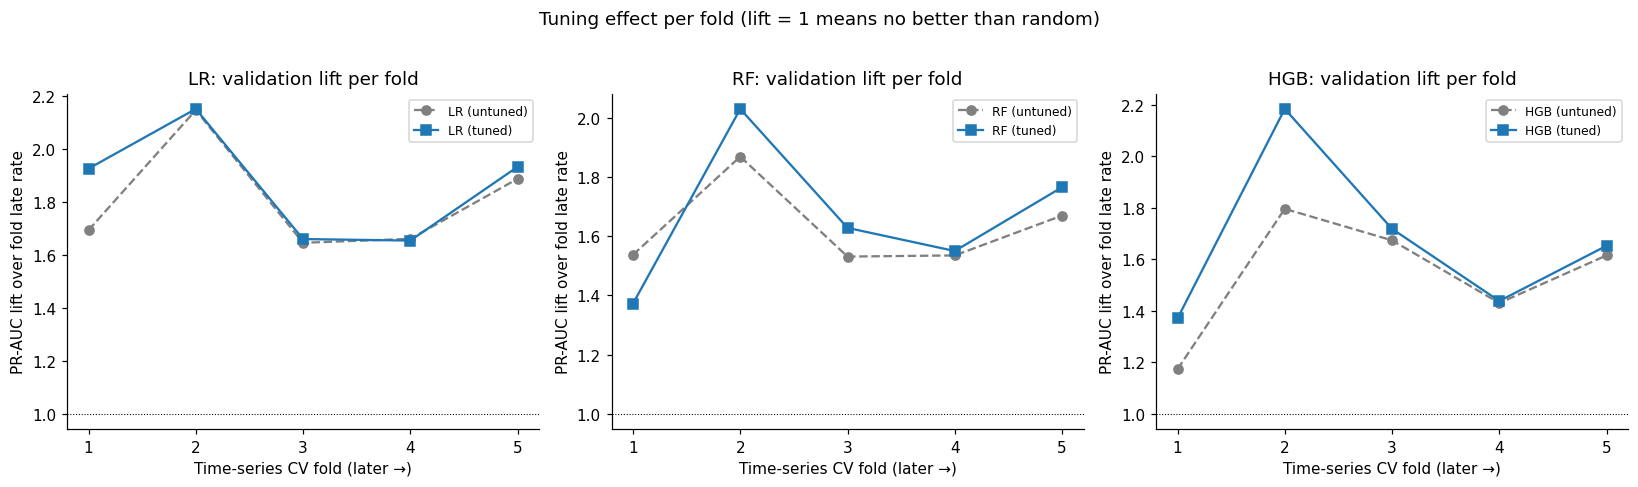

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=False)
pairs = [("LR", "LR (untuned)", "LR (tuned)"), ("RF", "RF (untuned)", "RF (tuned)"),
         ("HGB", "HGB (untuned)", "HGB (tuned)")]
for ax, (short, before, after) in zip(axes, pairs):
    for name, style in [(before, dict(ls="--", marker="o", color="grey")),
                        (after, dict(ls="-", marker="s", color="tab:blue"))]:
        d = all_single[all_single.model == name]
        ax.plot(d.fold, d.lift, label=name, **style)
    ax.axhline(1, color="black", lw=0.7, ls=":")
    ax.set(title=f"{short}: validation lift per fold", xlabel="Time-series CV fold (later →)",
           ylabel="PR-AUC lift over fold late rate", xticks=range(1, 6))
    ax.legend(fontsize=8)
fig.suptitle("Tuning effect per fold (lift = 1 means no better than random)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "5_1_tuned_vs_untuned_by_fold.png", bbox_inches="tight")
plt.show()

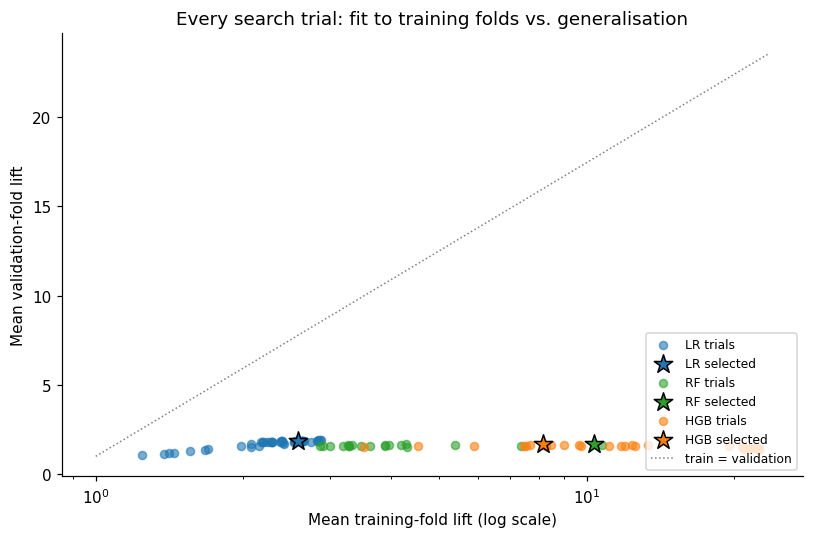

In [14]:
# Overfitting picture: every trial of every search, train lift vs validation lift.
fig, ax = plt.subplots(figsize=(7.5, 5))
for (name, search), color in zip([("LR", lr_search), ("RF", rf_search), ("HGB", hgb_search)],
                                 ["tab:blue", "tab:green", "tab:orange"]):
    cvr = search.cv_results_
    val_lift = np.mean([cvr[f"split{k}_test_pr_auc"] / VAL_RATE[k] for k in range(5)], axis=0)
    tr_lift = np.mean([cvr[f"split{k}_train_pr_auc"] / TRAIN_RATE[k] for k in range(5)], axis=0)
    ax.scatter(tr_lift, val_lift, s=28, alpha=0.6, color=color, label=f"{name} trials")
    b = search.best_index_
    ax.scatter(tr_lift[b], val_lift[b], s=160, marker="*", color=color, edgecolor="black",
               label=f"{name} selected")
lim = ax.get_xlim()
ax.plot([1, lim[1]], [1, lim[1]], color="grey", ls=":", lw=1, label="train = validation")
ax.set(xscale="log", xlabel="Mean training-fold lift (log scale)",
       ylabel="Mean validation-fold lift",
       title="Every search trial: fit to training folds vs. generalisation")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "5_1_train_vs_val_lift_all_trials.png", bbox_inches="tight")
plt.show()

**Results of the search** (5-fold time-series CV with a 2,000-order gap, training period only)

| Model | Selected configuration | CV PR-AUC | CV lift | Recall@10% | Train/val lift |
|---|---|---|---|---|---|
| LR untuned → **tuned** | L1, C = 0.157, no class weight, one-hot `min_frequency` = 20 | 0.158 → **0.161** | 1.81 → **1.87** | 21.5% → **22.5%** | 1.52 → **1.39** |
| RF untuned → tuned | depth 12, leaf ≥ 18, `sqrt` features, balanced_subsample | 0.142 → 0.149 | 1.63 → 1.67 | 18.9% → 19.8% | 6.23 → 6.19 |
| HGB untuned → tuned | lr 0.014, 395 trees, 27 leaves, leaf ≥ 227, L2 4.9, 44% features | 0.139 → 0.146 | 1.54 → 1.67 | 17.1% → 18.4% | 12.02 → 4.87 |
| HGB native categorical | same as tuned HGB, ordinal + native splits | 0.143 | 1.61 | 17.8% | 6.33 |

**Interpretation**

1. **Logistic regression is still best, and its tuning gain is small but consistent.** Every metric moved the right way and overfitting fell (1.52 → 1.39). The search chose an L1 penalty, which switches off inputs the model does not need (5.4 shows how many). The top eight LR configurations all score 0.160 to 0.161, whether L1 or L2, weighted or not. That is a flat plateau: LR was already close to its best, and which configuration wins is close to arbitrary. We read the gain as "at least as good and more stable", not as a breakthrough.
2. **Class weighting does not matter for ranking.** Weighted and unweighted configurations are interleaved in LR's top eight. Reweighting mainly shifts the intercept, which moves every score together and leaves the order unchanged.
3. **Regularisation helped boosting the most.** HGB's best settings are slow (learning rate 0.014), coarse (≥ 227 orders per leaf), heavily L2-penalised and feature-subsampled. That cut its overfitting ratio from 12.0 to 4.9 and raised validation lift by 8%.
4. **The scatter plot is the key finding here.** Across all 90 trials, training-fold lift ranges from about 1.2× to over 20×. Validation lift stays in a narrow band of about 1.1 to 1.9× for every family. More model capacity buys memorisation, not generalisation. **The ceiling is set by the information in the features, not by the algorithm or its settings.** This matches Jingyu's 4.3.4 result that 66.2% of the last fold's late orders were missed by all three models (partly because a 10% budget could flag at most 53% of that fold's late orders). It also points to where the next gain is: changing *what the model sees*. 5.1.6 tests exactly that.
5. **What did not work:** native categorical splits for HGB (0.143 vs 0.146 with one-hot). With 71 product categories, native splits let each tree carve out category groups that fit the training months (train/val lift 6.3) and do not transfer. One-hot with rare-category grouping is kept.
6. **Caveat:** the best of N random trials is slightly optimistic as an estimate of performance. That is one reason the final model is judged only on the untouched test set (5.3).

### 5.1.6 Feature-set choice: should `purchase_month` be dropped?

A teammate flagged that `purchase_month` may be **memorising which months were bad** rather than learning a repeating seasonal pattern. The table below supports that worry. The training period covers only 15 months, so January to March appear in both 2017 and 2018 and every other month appears only once. The same calendar month can carry completely different risk in the two years (February: 3.0% late in 2017, 14.1% in 2018; March: 4.6% vs 19.0%). The 2018 spikes were one-off events, not seasonality. Worse, the test months (April to July) were seen only in 2017, so whatever the model learned about them comes from a single year.

The checklist says to treat data-preparation choices as hyperparameters, so the feature set is tested the same way as everything else. Each tuned configuration is scored with and without `purchase_month` on the same five folds.

**Decision rule, fixed before the results.** This applies the same "complexity has to earn its place" principle as the model-selection rule in 5.2. `purchase_month` is **kept only if** the version with it beats the version without it on at least 4 of 5 folds **and** its mean PR-AUC gain is larger than one standard error of the paired differences. Otherwise it is dropped. The rule is applied separately to each model family, because what is noise to a linear model can be a memorisation handle for a tree.

*Limitation of the test:* the other hyperparameters were tuned with `purchase_month` present, which, if anything, slightly favours keeping it.

In [15]:
month_rates = (train.assign(year=train.order_purchase_timestamp.dt.year)
               .pivot_table(index="purchase_month", columns="year", values=config.TARGET,
                            aggfunc=["mean", "size"]))
month_rates.columns = [f"late rate {y}" if s == "mean" else f"orders {y}" for s, y in month_rates.columns]
month_rates

,late rate 2017,late rate 2018,orders 2017,orders 2018
purchase_month,,,,
1,0.029,0.057,748.000,7069.000
2,0.030,0.141,1641.000,6555.000
3,0.046,0.190,2546.000,7002.000
4,0.066,NaN,2303.000,NaN
5,0.030,NaN,3545.000,NaN
6,0.030,NaN,3135.000,NaN
7,0.028,NaN,3872.000,NaN
8,0.029,NaN,4193.000,NaN
9,0.044,NaN,4150.000,NaN


In [16]:
def tuned(search, drop_month: bool = False):
    """Unfitted copy of a search's selected configuration, optionally without purchase_month."""
    est = clone(search.best_estimator_)
    if drop_month:
        onehot = est.named_steps["pre"].transformers[-1][1].named_steps["onehot"]
        est.set_params(pre=make_preprocess(min_frequency=onehot.min_frequency, drop_month=True))
    if isinstance(est.named_steps["clf"], RandomForestClassifier):
        est.set_params(clf__n_jobs=-1)  # all cores outside the search
    return est


SEARCHES = {"LR": lr_search, "RF": rf_search, "HGB": hgb_search}
t0 = time.time()
nomonth_folds = pd.concat([cv_eval(tuned(s, drop_month=True), f"{k} (tuned, no month)")
                           for k, s in SEARCHES.items()], ignore_index=True)
print(f"Without-month CV done in {time.time() - t0:,.0f}s")

rows = []
for k in SEARCHES:
    with_m = tuned_folds[tuned_folds.model == f"{k} (tuned)"].set_index("fold")
    without = nomonth_folds[nomonth_folds.model == f"{k} (tuned, no month)"].set_index("fold")
    gain = with_m["pr_auc"] - without["pr_auc"]          # what keeping the month buys
    se = gain.std(ddof=1) / np.sqrt(len(gain))
    keep = bool((gain > 0).sum() >= 4 and gain.mean() > se)
    rows.append({"model": k,
                 "PR-AUC with month": with_m["pr_auc"].mean(),
                 "PR-AUC without": without["pr_auc"].mean(),
                 "lift with": with_m["lift"].mean(), "lift without": without["lift"].mean(),
                 "gain from keeping month": gain.mean(), "SE of gain": se,
                 "folds where month helps": int((gain > 0).sum()),
                 "train/val lift with": (with_m["train_lift"] / with_m["lift"]).mean(),
                 "train/val lift without": (without["train_lift"] / without["lift"]).mean(),
                 "decision": "keep" if keep else "drop"})
month_test = pd.DataFrame(rows).set_index("model")
month_test

Without-month CV done in 99s


,PR-AUC with month,PR-AUC without,lift with,lift without,gain from keeping month,SE of gain,folds where month helps,train/val lift with,train/val lift without,decision
model,,,,,,,,,,
LR,0.161,0.168,1.866,1.979,-0.007,0.008,3,1.406,1.241,drop
RF,0.149,0.161,1.669,1.803,-0.012,0.008,1,6.304,5.420,drop
HGB,0.146,0.157,1.673,1.789,-0.010,0.010,2,4.958,4.371,drop


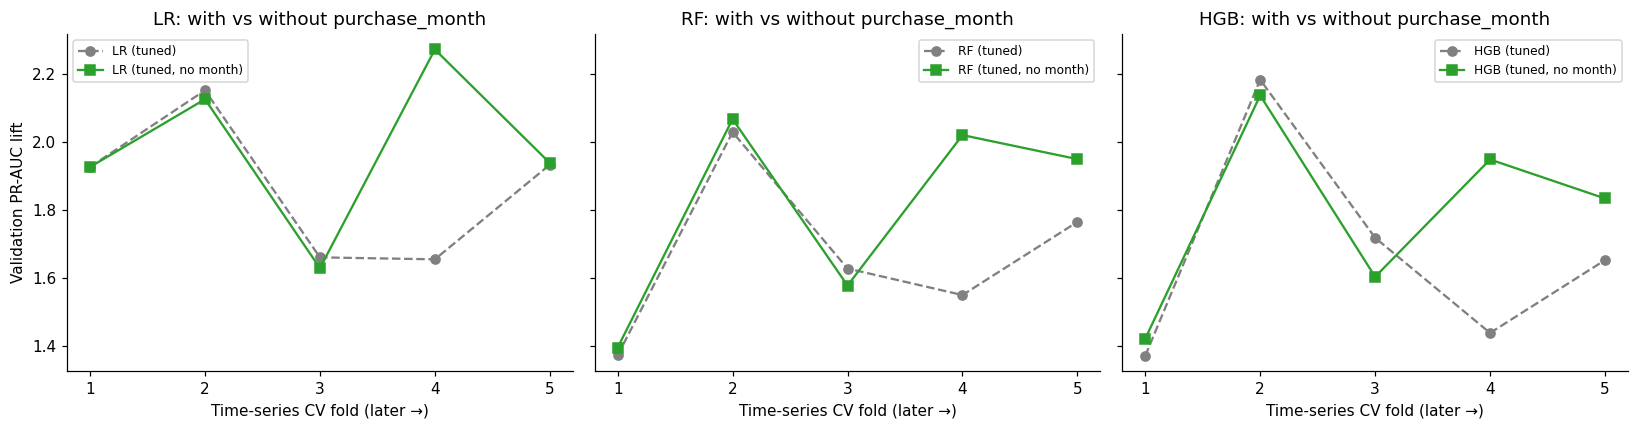

Feature set carried forward: {'LR': 'without purchase_month', 'RF': 'without purchase_month', 'HGB': 'without purchase_month'}


In [17]:
DROP_MONTH = {k: month_test.loc[k, "decision"] == "drop" for k in SEARCHES}
CHOSEN = {k: tuned(s, drop_month=DROP_MONTH[k]) for k, s in SEARCHES.items()}
CHOSEN_NAME = {k: f"{k} (tuned, no month)" if DROP_MONTH[k] else f"{k} (tuned)" for k in SEARCHES}
pool = pd.concat([tuned_folds, nomonth_folds], ignore_index=True)
chosen_folds = pool[pool.model.isin(CHOSEN_NAME.values())].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k in zip(axes, SEARCHES):
    for name, style in [(f"{k} (tuned)", dict(marker="o", ls="--", color="grey")),
                        (f"{k} (tuned, no month)", dict(marker="s", ls="-", color="tab:green"))]:
        d = pool[pool.model == name]
        ax.plot(d.fold, d.lift, label=name, **style)
    ax.set(title=f"{k}: with vs without purchase_month", xlabel="Time-series CV fold (later →)",
           xticks=range(1, 6))
    ax.legend(fontsize=8)
axes[0].set_ylabel("Validation PR-AUC lift")
fig.tight_layout()
fig.savefig(FIG_DIR / "5_1_6_purchase_month_by_fold.png", bbox_inches="tight")
plt.show()
print("Feature set carried forward:", {k: "without purchase_month" if v else "with purchase_month"
                                       for k, v in DROP_MONTH.items()})

**Result: `purchase_month` is dropped for all three model families.**

| Model | PR-AUC with → without | Lift with → without | Folds where the month helps | Overfitting (train/val lift)* with → without |
|---|---|---|---|---|
| LR | 0.161 → **0.168** | 1.87 → **1.98** | 3 of 5 | 1.41 → **1.24** |
| RF | 0.149 → **0.161** | 1.67 → **1.80** | 1 of 5 | 6.30 → **5.42** |
| HGB | 0.146 → **0.157** | 1.67 → **1.79** | 2 of 5 | 4.96 → **4.37** |

<sub>*Mean of the per-fold ratios, so it differs slightly from the ratio of means in the 5.1.5 table.</sub>

**Interpretation**

1. **Dropping one feature did more than all 90 tuning trials.** For LR, tuning added +0.003 PR-AUC; removing `purchase_month` added +0.007 on top. For RF and HGB the gain (+0.011 to +0.012) is larger than their whole tuning gain. Overfitting fell for every model. This is the clearest *what worked* result in the section: a feature that encodes "which period was bad" is worse than no feature.
2. **The fold plot shows the mechanism.** The gain is concentrated in fold 4, which validates on 26 Dec 2017 to 14 Feb 2018. The only January and February the model had seen were 2017's, at about 3% late. So `purchase_month` told it "January and February are safe" exactly when they turned into the 2018 spike. For the trees, the gain carries on into fold 5 (mid-February to March 2018), the same story. On the folds whose months behaved like before (1 to 3), the column makes no difference. It adds nothing when the past repeats, and it hurts when the past does not.
3. **How strong is the evidence?** For RF the case is clear: the month helps on only 1 of 5 folds, and dropping it gains more than one standard error (0.012 vs 0.008). For LR and HGB the gain is about one standard error, so the data alone would not *force* the decision. But the rule puts the burden of proof on keeping the column, and it does not meet it. Add the 2017-vs-2018 table and the drop is the right call: there is no evidence the month helps, clear evidence it can mislead, and the test months (April to July) were only ever seen in one year.
4. **Seasonality is not being thrown away.** Real calendar effects such as Black Friday or holidays would be better captured by an explicit holiday or peak-season flag, which can generalise across years. That stays on the extra-data list (README 2.6 and section 7).

From here on, every model and ensemble uses the feature set without `purchase_month`.

## 5.2 Ensembles

Jingyu's overlap analysis (4.3.4) found that on the last fold each model caught some late orders the others missed (LR 163, RF 60, HGB 72 uniquely). Whether that translates into a better **single ranking** under a fixed review budget is an empirical question, so we test it with the same CV.

**Ensembles tried (all built from the tuned configurations):**

1. **Soft voting, LR + RF + HGB**: average of predicted probabilities.
2. **Soft voting, LR + HGB**: the two most different model families (linear vs boosted trees).
3. **Weighted soft voting (LR × 2, RF, HGB)**: leans on the strongest single model.
4. **Rank averaging, LR + RF + HGB**: averages each model's *rank* of an order instead of its probability. Models trained with and without class weights produce probabilities on very different scales, so in plain soft voting the model with inflated probabilities silently dominates. Ranks remove that, and ranking is all the ops team needs.

**Why no stacking.** `StackingClassifier` trains its meta-model on out-of-fold predictions produced with `cross_val_predict`, which needs folds that partition the data. `TimeSeriesSplit` does not, and a shuffled K-fold would let the meta-model learn from future orders, which breaks D6/D7. A leak-free stack would need a third time slice we do not have room for, so we stop at voting.

**Selection rule, fixed before looking at the results below.** Pick the candidate with the highest mean CV PR-AUC. A more complex candidate (ensemble or tree model) replaces the tuned logistic regression only if it is **better on at least 4 of the 5 folds *and* its mean gain is larger than one standard error of the paired fold differences**. Otherwise we keep the simpler model: it is faster, its coefficients can be shown to the ops team, and a gain inside the noise would not survive the train-to-test drift.

In [18]:
class RankAverageClassifier(ClassifierMixin, BaseEstimator):
    """Averages the percentile rank each base model gives an order.

    Output is in [0, 1] and is a ranking score, not a calibrated probability.
    """

    def __init__(self, estimators):
        self.estimators = estimators

    def fit(self, X, y):
        self.estimators_ = [clone(est).fit(X, y) for _, est in self.estimators]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        ranks = [pd.Series(est.predict_proba(X)[:, 1]).rank(pct=True).to_numpy()
                 for est in self.estimators_]
        p = np.mean(ranks, axis=0)
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


LR, RF, HGB = CHOSEN["LR"], CHOSEN["RF"], CHOSEN["HGB"]
ensembles = {
    "Soft vote LR+RF+HGB": VotingClassifier(
        [("lr", clone(LR)), ("rf", clone(RF)), ("hgb", clone(HGB))],
        voting="soft"),
    "Soft vote LR+HGB": VotingClassifier(
        [("lr", clone(LR)), ("hgb", clone(HGB))], voting="soft"),
    "Weighted vote 2LR+RF+HGB": VotingClassifier(
        [("lr", clone(LR)), ("rf", clone(RF)), ("hgb", clone(HGB))],
        voting="soft", weights=[2, 1, 1]),
    "Rank average LR+RF+HGB": RankAverageClassifier(
        [("lr", clone(LR)), ("rf", clone(RF)), ("hgb", clone(HGB))]),
}
t0 = time.time()
ens_folds = pd.concat([cv_eval(m, n) for n, m in ensembles.items()], ignore_index=True)
print(f"Ensemble CV done in {time.time() - t0:,.0f}s")

compare_folds = pd.concat([chosen_folds, ens_folds], ignore_index=True)
compare_summary = summarize(compare_folds)
pretty(compare_summary)

Ensemble CV done in 309s


,PR-AUC,Lift,Recall@10%,Recall@20%,ROC-AUC,Train lift,Train/val lift
model,,,,,,,
Weighted vote 2LR+RF+HGB,0.168 ± 0.125,1.945 ± 0.294,0.231 ± 0.029,0.400 ± 0.041,0.670 ± 0.037,6.766 ± 3.006,3.480
"LR (tuned, no month)",0.168 ± 0.121,1.979 ± 0.242,0.237 ± 0.027,0.399 ± 0.039,0.678 ± 0.033,2.415 ± 0.143,1.220
Soft vote LR+HGB,0.168 ± 0.121,1.961 ± 0.286,0.234 ± 0.025,0.403 ± 0.038,0.674 ± 0.034,5.584 ± 2.180,2.850
Rank average LR+RF+HGB,0.167 ± 0.126,1.913 ± 0.286,0.233 ± 0.027,0.400 ± 0.046,0.673 ± 0.036,5.915 ± 2.029,3.090
Soft vote LR+RF+HGB,0.166 ± 0.125,1.904 ± 0.317,0.225 ± 0.035,0.389 ± 0.043,0.666 ± 0.038,7.851 ± 3.647,4.120
"RF (tuned, no month)",0.161 ± 0.127,1.803 ± 0.299,0.207 ± 0.039,0.377 ± 0.047,0.656 ± 0.041,9.215 ± 4.205,5.110
"HGB (tuned, no month)",0.157 ± 0.118,1.789 ± 0.282,0.215 ± 0.036,0.370 ± 0.042,0.657 ± 0.037,7.522 ± 3.319,4.200


In [19]:
# Paired comparison against the tuned LR: same folds, so differences cancel fold difficulty.
LR_NAME = CHOSEN_NAME["LR"]
ref = compare_folds[compare_folds.model == LR_NAME].set_index("fold")
rows = []
for name, d in compare_folds.groupby("model", sort=False):
    if name == LR_NAME:
        continue
    diff = d.set_index("fold")["pr_auc"] - ref["pr_auc"]
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    rows.append({"model": name, "mean_gain_vs_LR": diff.mean(), "se_of_gain": se,
                 "folds_better": int((diff > 0).sum()),
                 "lift_gain_vs_LR": (d.set_index("fold")["lift"] - ref["lift"]).mean(),
                 "passes_rule": bool((diff > 0).sum() >= 4 and diff.mean() > se)})
paired = pd.DataFrame(rows).set_index("model").sort_values("mean_gain_vs_LR", ascending=False)
paired

,mean_gain_vs_LR,se_of_gain,folds_better,lift_gain_vs_LR,passes_rule
model,,,,,
Weighted vote 2LR+RF+HGB,0.000,0.002,3,-0.034,False
Soft vote LR+HGB,-0.000,0.002,2,-0.018,False
Rank average LR+RF+HGB,-0.001,0.004,3,-0.066,False
Soft vote LR+RF+HGB,-0.002,0.003,2,-0.075,False
"RF (tuned, no month)",-0.007,0.004,1,-0.176,False
"HGB (tuned, no month)",-0.011,0.004,1,-0.190,False


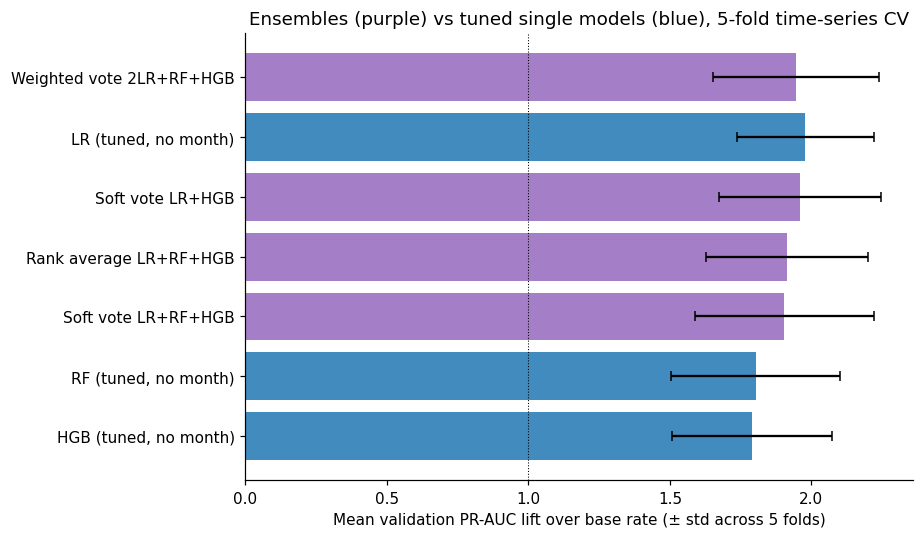

In [20]:
order = compare_summary.index.tolist()[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
colors = ["tab:purple" if n in ensembles else "tab:blue" for n in order]
ax.barh(order, compare_summary.loc[order, "lift_mean"],
        xerr=compare_summary.loc[order, "lift_std"], color=colors, alpha=0.85, capsize=3)
ax.axvline(1, color="black", lw=0.7, ls=":")
ax.set(xlabel="Mean validation PR-AUC lift over base rate (± std across 5 folds)",
       title="Ensembles (purple) vs tuned single models (blue), 5-fold time-series CV")
fig.tight_layout()
fig.savefig(FIG_DIR / "5_2_ensemble_vs_single.png", bbox_inches="tight")
plt.show()

In [21]:
# Apply the pre-registered selection rule.
best_by_cv = compare_summary.index[0]
challengers = paired[paired.passes_rule]
if best_by_cv == LR_NAME or challengers.empty:
    FINAL_NAME = LR_NAME
else:
    FINAL_NAME = challengers.index[0]

candidates = {**{CHOSEN_NAME[k]: CHOSEN[k] for k in CHOSEN},
              "HGB tuned (native categorical)": hgb_native, **ensembles}
FINAL_MODEL = clone(candidates[FINAL_NAME])
print(f"Highest mean CV PR-AUC: {best_by_cv}")
print(f"Candidates passing the rule against tuned LR: {list(challengers.index) or 'none'}")
print(f"FINAL MODEL (locked before the test set is opened): {FINAL_NAME}")

Highest mean CV PR-AUC: Weighted vote 2LR+RF+HGB
Candidates passing the rule against tuned LR: none
FINAL MODEL (locked before the test set is opened): LR (tuned, no month)


**Interpretation**

* **No ensemble beats the tuned logistic regression without the month.** The weighted vote (2 × LR + RF + HGB) ties it on mean CV PR-AUC (0.168 vs 0.168; gain +0.000, standard error 0.002, better on 3 of 5 folds). Its lift is lower (1.95 vs 1.98), and so is its recall@10% (23.1% vs 23.7%). The other three ensembles are below LR on every summary metric.
* **Why averaging does not help here.** Ensembles gain when their members make *different* mistakes that average out. Jingyu's 4.3.4 showed some unique catches per model, but 5.1 showed the tree models are clearly weaker (lift 1.79 to 1.80 vs 1.98) and overfit more. Averaging LR with weaker, noisier rankings dilutes it about as much as the diversity helps.
* **Ensembles inherit the trees' overfitting.** Train/val lift is 2.9 to 4.1 for the ensembles vs 1.22 for LR alone.
* **Rank averaging behaved in the middle of the pack** (lift 1.91). Giving every model an equal vote on rank helped slightly over plain three-way soft voting (1.90), but not enough to beat LR.
* **Decision, by the rule fixed in advance: the final model is the tuned logistic regression without `purchase_month`.** It is also the simplest candidate, fits in about a second, and its coefficients can be shown to the ops team.

## 5.3 Test-set results compared with the baselines

The final model is now locked (cell above). This section is the **only** place the test labels are read. The final model and the two baselines are re-fitted on the training period and scored once on April to July 2018.

**Gap before the test period.** The same 2,000-order gap used between CV folds is applied at the train/test boundary: the last 2,000 training orders (bought from 22 to 31 March 2018) are left out of the final fit. On 1 April most of them had not been delivered yet, so in real use their labels would not be known. Keeping them would let the model learn from outcomes it could not have seen. The model's configuration is unchanged; only these rows are removed.

*Process notes.*
1. An earlier draft of this notebook was run before the team added the 2,000-order gap to the shared splitter. The search, the selection rule and this evaluation were then re-run from scratch on the current splitter, with the rule unchanged. The draft's results are not used anywhere.
2. The first locked test run fitted the final model on all training orders up to 31 March. In review, the team agreed to apply the CV gap at the test boundary as well, for consistency. This changes only which training rows are used, not the model or its settings. It was agreed on principle, and it made the test score slightly worse, not better. Both runs are shown below: the gap version is the official result, and the earlier run is kept in 5.3.1 so nothing is hidden.

For transparency, the other tuned candidates are also scored on the test set **after** the choice was locked. Those rows are reported, not used: switching to whichever looks best on the test set would turn the test set into a validation set and make the reported error optimistic (checklist: *"don't tweak your model after measuring the generalization error"*).

In [22]:
class RandomRanker(ClassifierMixin, BaseEstimator):
    """B0: no-skill baseline, random scores (Fidan, 4.1)."""

    def __init__(self, random_state=RS):
        self.random_state = random_state

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = np.random.default_rng(self.random_state).random(len(X))
        return np.c_[1 - p, p]


b1_pre = ColumnTransformer([
    ("days", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]),
     ["promised_days_from_approval"]),
    ("state", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100),
     ["customer_state"]),
], sparse_threshold=0)

baselines = {
    "B0 Random": RandomRanker(),
    "B1 LogReg (promised days + state)": Pipeline(
        [("pre", b1_pre), ("clf", LogisticRegression(max_iter=1000, random_state=RS))]),
}
TEST_RATE = y_test.mean()
N_DAYS = (test.order_purchase_timestamp.max() - test.order_purchase_timestamp.min()).days + 1


def test_metrics(y, s):
    k10 = int(np.ceil(0.10 * len(y)))
    r10 = recall_at_budget(y, s, 0.10)
    return {"PR-AUC": average_precision_score(y, s),
            "Lift": average_precision_score(y, s) / y.mean(),
            "ROC-AUC": roc_auc_score(y, s),
            "Recall@5%": recall_at_budget(y, s, 0.05),
            "Recall@10%": r10,
            "Recall@20%": recall_at_budget(y, s, 0.20),
            "Precision@10%": r10 * y.sum() / k10}


# ---- training rows for the final fit: drop the last CV_GAP orders (labels unknown on 1 April)
FIT_N = len(X_train) - config.CV_GAP
X_fit, y_fit = X_train.iloc[:FIT_N], y_train.iloc[:FIT_N]
assert train.order_purchase_timestamp.iloc[FIT_N - 1] < train.order_purchase_timestamp.iloc[FIT_N]
print(f"Final fit: {FIT_N:,} orders bought {train.order_purchase_timestamp.iloc[0]:%d %b %Y} to "
      f"{train.order_purchase_timestamp.iloc[FIT_N - 1]:%d %b %Y %H:%M}; "
      f"{config.CV_GAP:,} later orders (from {train.order_purchase_timestamp.iloc[FIT_N]:%d %b %Y %H:%M}) left out.")

# ---- the single, locked evaluation ------------------------------------------------
final_fitted = clone(FINAL_MODEL).fit(X_fit, y_fit)
test_scores = {FINAL_NAME: final_fitted.predict_proba(X_test)[:, 1]}
fitted = {FINAL_NAME: final_fitted}
for name, model in baselines.items():
    fitted[name] = clone(model).fit(X_fit, y_fit)
    test_scores[name] = fitted[name].predict_proba(X_test)[:, 1]

headline = pd.DataFrame({n: test_metrics(y_test.to_numpy(), s) for n, s in test_scores.items()}).T
headline.index.name = f"Test Apr to Jul 2018 (n={len(y_test):,}, late rate {TEST_RATE:.1%})"
headline

Final fit: 62,038 orders bought 05 Jan 2017 to 22 Mar 2018 10:10; 2,000 later orders (from 22 Mar 2018 10:11) left out.


,PR-AUC,Lift,ROC-AUC,Recall@5%,Recall@10%,Recall@20%,Precision@10%
"Test Apr to Jul 2018 (n=21,333, late rate 4.1%)",,,,,,,
"LR (tuned, no month)",0.126,3.070,0.761,0.220,0.361,0.540,0.148
B0 Random,0.042,1.013,0.492,0.049,0.102,0.196,0.042
B1 LogReg (promised days + state),0.109,2.664,0.733,0.201,0.336,0.502,0.138


In [23]:
# Paired bootstrap: is the final model's edge over B1 bigger than test-set sampling noise?
yt = y_test.to_numpy()
B1_NAME = "B1 LogReg (promised days + state)"


def paired_bootstrap(s_model, s_base, n_boot=1000):
    """Resample test orders with replacement; same resample for both models, so the gap is paired."""
    rng = np.random.default_rng(RS)
    boot = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(yt), len(yt))
        yb = yt[idx]
        boot.append((average_precision_score(yb, s_model[idx]) - average_precision_score(yb, s_base[idx]),
                     recall_at_budget(yb, s_model[idx], 0.10) - recall_at_budget(yb, s_base[idx], 0.10)))
    boot = np.array(boot)
    return pd.DataFrame({
        "point estimate": [average_precision_score(yt, s_model) - average_precision_score(yt, s_base),
                           recall_at_budget(yt, s_model) - recall_at_budget(yt, s_base)],
        "95% CI low": np.percentile(boot, 2.5, axis=0),
        "95% CI high": np.percentile(boot, 97.5, axis=0),
        "share of resamples > 0": (boot > 0).mean(axis=0),
    }, index=["PR-AUC gain over B1", "Recall@10% gain over B1"])


boot_table = paired_bootstrap(test_scores[FINAL_NAME], test_scores[B1_NAME])
boot_table

,point estimate,95% CI low,95% CI high,share of resamples > 0
PR-AUC gain over B1,0.017,0.006,0.027,1.000
Recall@10% gain over B1,0.025,-0.004,0.048,0.958


### 5.3.1 Effect of the train/test gap (first locked run vs official run)

The same locked model and B1, fitted once on all 64,038 training orders (the first locked run) and once with the gap (the official run above). Nothing else differs.

In [24]:
nogap_scores = {name: clone(model).fit(X_train, y_train).predict_proba(X_test)[:, 1]
                for name, model in [(FINAL_NAME, FINAL_MODEL), (B1_NAME, baselines[B1_NAME])]}
nogap_boot = paired_bootstrap(nogap_scores[FINAL_NAME], nogap_scores[B1_NAME])


def run_row(scores, boot):
    m, b = test_metrics(yt, scores[FINAL_NAME]), test_metrics(yt, scores[B1_NAME])
    ci = lambda r: f"{boot.loc[r, 'point estimate']:+.3f} ({boot.loc[r, '95% CI low']:+.3f} to {boot.loc[r, '95% CI high']:+.3f})"
    return {"Final PR-AUC": m["PR-AUC"], "Final lift": m["Lift"],
            "Final recall@10%": m["Recall@10%"],
            "Late orders caught (final)": int(round(m["Recall@10%"] * yt.sum())),
            "B1 recall@10%": b["Recall@10%"],
            "Late orders caught (B1)": int(round(b["Recall@10%"] * yt.sum())),
            "PR-AUC gain over B1 (95% CI)": ci("PR-AUC gain over B1"),
            "Recall@10% gain over B1 (95% CI)": ci("Recall@10% gain over B1")}


gap_compare = pd.DataFrame({
    "First locked run (no gap, 64,038 orders)": run_row(nogap_scores, nogap_boot),
    f"Official run (gap, {FIT_N:,} orders)": run_row(test_scores, boot_table),
})
gap_compare

,"First locked run (no gap, 64,038 orders)","Official run (gap, 62,038 orders)"
Final PR-AUC,0.131,0.126
Final lift,3.191,3.070
Final recall@10%,0.374,0.361
Late orders caught (final),328,316
B1 recall@10%,0.341,0.336
Late orders caught (B1),299,294
PR-AUC gain over B1 (95% CI),+0.021 (+0.010 to +0.031),+0.017 (+0.006 to +0.027)
Recall@10% gain over B1 (95% CI),+0.033 (+0.007 to +0.060),+0.025 (-0.004 to +0.048)


In [25]:
# Reported only, after the choice was locked: the other candidates on the same test set.
others = {"LR (untuned)": untuned["LR (untuned)"],
          **{CHOSEN_NAME[k]: CHOSEN[k] for k in CHOSEN}, **ensembles}
others = {n: m for n, m in others.items() if n != FINAL_NAME}
for name, model in others.items():
    fitted[name] = clone(model).fit(X_fit, y_fit)
    test_scores[name] = fitted[name].predict_proba(X_test)[:, 1]
report_only = pd.DataFrame({n: test_metrics(yt, test_scores[n]) for n in others}).T
report_only["CV PR-AUC (selection)"] = compare_summary["pr_auc_mean"].reindex(report_only.index)
report_only["CV PR-AUC (selection)"] = report_only["CV PR-AUC (selection)"].fillna(
    single_summary["pr_auc_mean"].reindex(report_only.index))
report_only["CV PR-AUC (selection)"] = report_only["CV PR-AUC (selection)"].fillna(
    summarize(nomonth_folds)["pr_auc_mean"].reindex(report_only.index))
report_only.sort_values("PR-AUC", ascending=False)

,PR-AUC,Lift,ROC-AUC,Recall@5%,Recall@10%,Recall@20%,Precision@10%,CV PR-AUC (selection)
Soft vote LR+HGB,0.132,3.217,0.761,0.219,0.361,0.519,0.148,0.168
Rank average LR+RF+HGB,0.131,3.185,0.754,0.225,0.337,0.523,0.138,0.167
Weighted vote 2LR+RF+HGB,0.130,3.157,0.754,0.226,0.344,0.530,0.141,0.168
LR (untuned),0.130,3.157,0.763,0.224,0.371,0.549,0.152,0.158
Soft vote LR+RF+HGB,0.127,3.103,0.748,0.219,0.336,0.522,0.138,0.166
"HGB (tuned, no month)",0.119,2.910,0.744,0.212,0.334,0.508,0.137,0.157
"RF (tuned, no month)",0.110,2.689,0.723,0.187,0.309,0.475,0.127,0.161


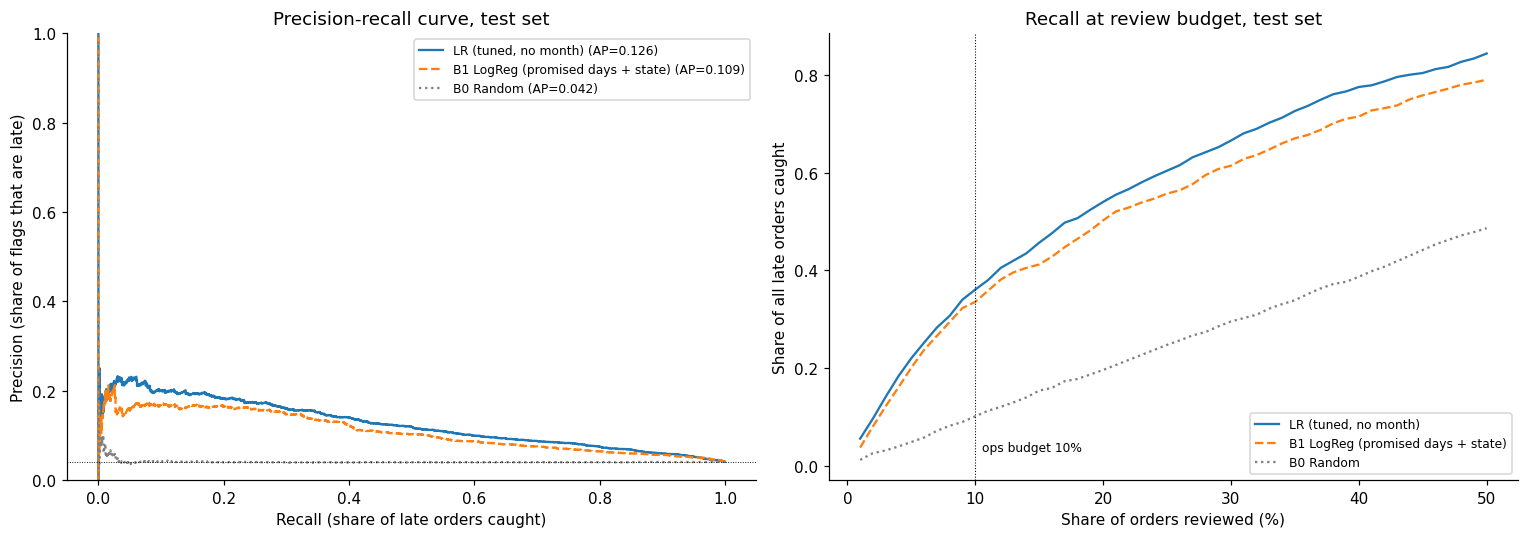

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_models = [(FINAL_NAME, "tab:blue", "-"),
               ("B1 LogReg (promised days + state)", "tab:orange", "--"),
               ("B0 Random", "grey", ":")]

ax = axes[0]
for name, color, ls in plot_models:
    p, r, _ = precision_recall_curve(yt, test_scores[name])
    ax.plot(r, p, color=color, ls=ls, label=f"{name} (AP={average_precision_score(yt, test_scores[name]):.3f})")
ax.axhline(TEST_RATE, color="black", lw=0.6, ls=":")
ax.set(xlabel="Recall (share of late orders caught)", ylabel="Precision (share of flags that are late)",
       title="Precision-recall curve, test set", ylim=(0, 1))
ax.legend(fontsize=8)

ax = axes[1]
budgets = np.linspace(0.01, 0.5, 50)
for name, color, ls in plot_models:
    ax.plot(budgets * 100, [recall_at_budget(yt, test_scores[name], b) for b in budgets],
            color=color, ls=ls, label=name)
ax.axvline(10, color="black", lw=0.7, ls=":")
ax.annotate("ops budget 10%", (10.5, 0.03), fontsize=8)
ax.set(xlabel="Share of orders reviewed (%)", ylabel="Share of all late orders caught",
       title="Recall at review budget, test set")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "5_3_test_pr_and_budget_curves.png", bbox_inches="tight")
plt.show()

In [27]:
# Stability within the test period: lift by purchase month.
monthly = []
months = test.order_purchase_timestamp.dt.to_period("M").to_numpy()
for m in pd.unique(months):
    mask = months == m
    row = {"month": str(m), "orders": int(mask.sum()), "late_rate": yt[mask].mean()}
    for name in [FINAL_NAME, "B1 LogReg (promised days + state)"]:
        row[f"lift {name}"] = average_precision_score(yt[mask], test_scores[name][mask]) / yt[mask].mean()
        row[f"recall@10% {name}"] = recall_at_budget(yt[mask], test_scores[name][mask])
    monthly.append(row)
monthly = pd.DataFrame(monthly).set_index("month")
monthly

,orders,late_rate,"lift LR (tuned, no month)","recall@10% LR (tuned, no month)",lift B1 LogReg (promised days + state),recall@10% B1 LogReg (promised days + state)
month,,,,,,
2018-04,6798,0.045,3.845,0.418,3.314,0.376
2018-05,6743,0.066,2.315,0.278,1.880,0.262
2018-06,5901,0.012,5.098,0.394,4.191,0.408
2018-07,1891,0.030,2.178,0.286,2.864,0.286


**Headline: the official test evaluation** (Apr to Jul 2018, 21,333 orders, 876 late; final model trained on 62,038 orders up to 22 March 2018)

| | **Final: tuned LR, no month** | B1 (promised days + state) | B0 random |
|---|---|---|---|
| PR-AUC | **0.126** | 0.109 | 0.042 |
| Lift over 4.1% base rate | **3.07x** | 2.66x | 1.01x |
| ROC-AUC | **0.761** | 0.733 | 0.492 |
| Recall at 5% / 10% / 20% reviewed | **22.0% / 36.1% / 54.0%** | 20.1% / 33.6% / 50.2% | 4.9% / 10.2% / 19.6% |
| Precision at 10% reviewed | **14.8%** | 13.8% | 4.2% |

**Effect of the gap (5.3.1).** The first locked run, trained on all orders up to 31 March, gave PR-AUC 0.131 and caught 328 late orders (B1: 299). With the gap it gives 0.126 and 316 (B1: 294). The change is small and goes against us, which is what you would expect from removing training rows closest to the test period. We report the gap version because it matches how the model would really be trained on 1 April.

**Interpretation**

1. **The final model beats both baselines on every metric.** The paired bootstrap (1,000 resamples of the test set) separates the two headline gains:
   - **PR-AUC gain over B1: +0.017 (95% CI +0.006 to +0.027)**, positive in 100% of resamples. The full model ranks late orders better overall, and that is clearly real.
   - **Recall@10% gain: +2.5 points (95% CI -0.4 to +4.8)**, positive in 96% of resamples. This gain is **positive but within the noise**: the interval includes zero, so with 876 late orders we cannot rule out that, at exactly the 10% budget, the full model and B1 catch about the same number.

   In plain terms, promised days and customer state already carry most of the signal. The extra features improve the ranking as a whole, and probably add a few more catches at the ops budget (316 vs 294), but that last part is not certain.
2. **No overfitting to the training period.** Test lift (3.1x) is above CV lift (2.0x), and the train/validation gap was small (1.22). If anything, LR is limited by bias, which fits the 5.1 finding that the ceiling is the features.
3. **Why test lift is higher than CV lift.** The training period contains system-wide spikes (Nov 2017, Feb to Mar 2018, up to 19% late). When almost everything is late, *which* order is late is close to random, so ranking is hard. The test months are calmer. The late orders that remain are the structural ones (tight promises, long cross-state routes), and those are what the model can see. Lift is therefore not comparable across periods without this context, as README section 7 already warns.
4. **Month by month,** the model beats B1 on both lift and recall@10% in April (lift 3.8 vs 3.3) and May (2.3 vs 1.9).
   - **May** has the highest late rate (6.6%) and a weak lift. This coincides with the nationwide truck drivers' strike in Brazil in late May 2018, an external shock that no approval-time feature can see.
   - **June and July are mixed.** In June the model has higher lift (5.1 vs 4.2), but B1 has slightly higher recall@10% (40.8% vs 39.4%). In July B1 has higher lift (2.9 vs 2.2), and recall@10% is tied at 28.6%. Both months have few late orders (about 71 and 57), so these comparisons are noisy. They are a reason to monitor monthly after deployment rather than trust one four-month average.
5. **The rows reported after the decision, read carefully.** After the choice was locked, the LR + HGB soft vote scored a slightly higher test PR-AUC (0.132 vs 0.126), with identical recall@10% (36.1%). The untuned LR catches slightly more in the top 10% (37.1%). Both say the same thing: **the differences between the leading candidates are inside the noise**, as CV already showed. Choosing among them by test score would turn the test set into a validation set and inflate the reported result, so the locked model stands.

## 5.4 The final model

### 5.4.1 What it uses: permutation importance on the test set

Importance is measured as the drop in **test** PR-AUC when one original column is shuffled (all its one-hot dummies move together). Using the test set here is legitimate because the model is already locked; it shows what the model relies on for the orders it will actually face. Jingyu's 4.2 did the same on the last validation fold; agreement between the two is a robustness check.

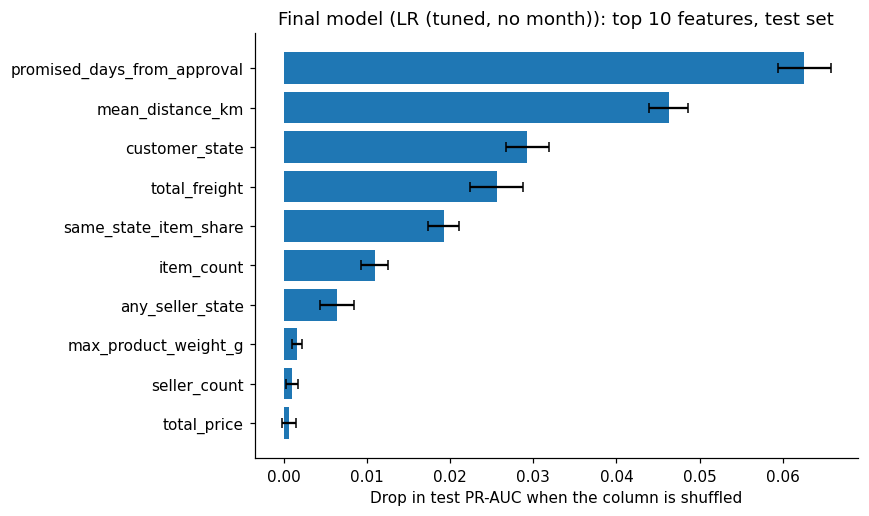

,feature,pr_auc_drop,std
0,promised_days_from_approval,0.063,0.003
1,mean_distance_km,0.046,0.002
2,customer_state,0.029,0.003
3,total_freight,0.026,0.003
4,same_state_item_share,0.019,0.002
5,item_count,0.011,0.002
6,any_seller_state,0.006,0.002
7,max_product_weight_g,0.002,0.001
8,seller_count,0.001,0.001
9,total_price,0.001,0.001


In [28]:
perm = permutation_importance(final_fitted, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=RS, n_jobs=2)
perm_df = (pd.DataFrame({"feature": X_test.columns, "pr_auc_drop": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("pr_auc_drop", ascending=False).reset_index(drop=True))

top = perm_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.feature, top.pr_auc_drop, xerr=top["std"], color="tab:blue", capsize=3)
ax.set(xlabel="Drop in test PR-AUC when the column is shuffled",
       title=f"Final model ({FINAL_NAME}): top 10 features, test set")
fig.tight_layout()
fig.savefig(FIG_DIR / "5_4_permutation_importance_test.png", bbox_inches="tight")
plt.show()
perm_df.head(10)

In [29]:
# If the final model is linear, translate its numeric coefficients into odds ratios.
clf = final_fitted.named_steps.get("clf") if hasattr(final_fitted, "named_steps") else None
if isinstance(clf, LogisticRegression):
    names = final_fitted.named_steps["pre"].get_feature_names_out()
    coefs = pd.Series(clf.coef_[0], index=names)
    numeric = coefs[coefs.index.str.startswith(("log_scale__", "fill_log_scale__", "scale__"))]
    odds = pd.DataFrame({"coefficient": numeric,
                         "odds ratio per +1 SD": np.exp(numeric)})
    odds.index = odds.index.str.split("__").str[-1]
    display(odds.reindex(odds.coefficient.abs().sort_values(ascending=False).index).head(10))
    print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")

,coefficient,odds ratio per +1 SD
promised_days_from_approval,-0.663,0.515
mean_distance_km,0.439,1.552
total_freight,0.298,1.347
same_state_item_share,-0.240,0.787
item_count,-0.193,0.824
seller_count,-0.133,0.876
max_product_weight_g,-0.056,0.946
total_price,0.055,1.056
approval_lag_hours,0.046,1.047
distinct_product_count,-0.042,0.959


Non-zero coefficients: 59 of 124


### 5.4.2 Probabilities versus ranking under drift

The late rate fell from 8.0% (train) to 4.1% (test). A model trained on the higher rate will over-state risk on the test period, so a **fixed probability threshold chosen on training data would flag the wrong number of orders**. The check below shows how far off that would be, and why the deployment rule should be *"flag the top 10% each day"* rather than *"flag anything above p"*.

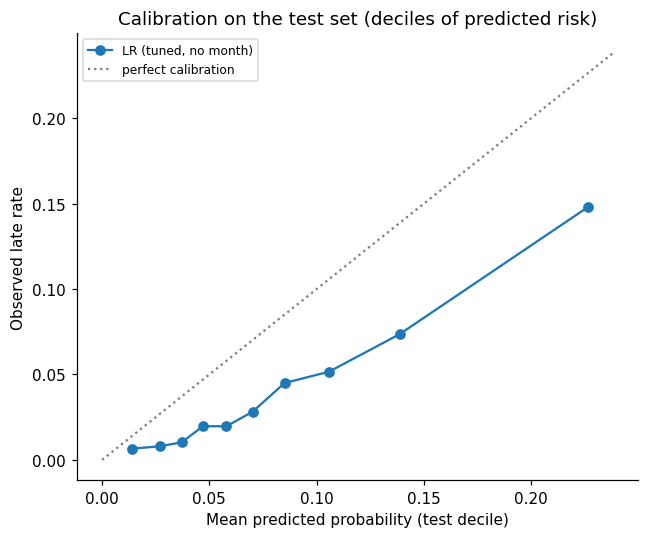

Mean predicted risk on test: 0.081 vs observed 0.041
A threshold that flags 10% of training orders flags 10.9% of test orders.


In [30]:
train_scores = final_fitted.predict_proba(X_fit)[:, 1]
threshold = np.quantile(train_scores, 0.90)           # flags 10% of training orders
share_flagged = (test_scores[FINAL_NAME] >= threshold).mean()

frac_pos, mean_pred = calibration_curve(yt, test_scores[FINAL_NAME], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(mean_pred, frac_pos, marker="o", label=FINAL_NAME)
lim = max(mean_pred.max(), frac_pos.max()) * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls=":", label="perfect calibration")
ax.set(xlabel="Mean predicted probability (test decile)", ylabel="Observed late rate",
       title="Calibration on the test set (deciles of predicted risk)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "5_4_test_calibration.png", bbox_inches="tight")
plt.show()

print(f"Mean predicted risk on test: {test_scores[FINAL_NAME].mean():.3f} vs observed {TEST_RATE:.3f}")
print(f"A threshold that flags 10% of training orders flags {share_flagged:.1%} of test orders.")

In [31]:
# Operational translation of the headline numbers.
k10 = int(np.ceil(0.10 * len(yt)))
caught = int(round(headline.loc[FINAL_NAME, "Recall@10%"] * yt.sum()))
caught_b1 = int(round(headline.loc["B1 LogReg (promised days + state)", "Recall@10%"] * yt.sum()))
print(f"Test period: {N_DAYS} days, {len(yt):,} orders (~{len(yt) / N_DAYS:.0f}/day), {yt.sum()} late.")
print(f"Reviewing the riskiest 10% = {k10:,} orders (~{k10 / N_DAYS:.0f} per day).")
print(f"Final model catches {caught} late orders; B1 catches {caught_b1}; random review catches ~{0.10 * yt.sum():.0f}.")
print(f"Hit rate of a flag: {headline.loc[FINAL_NAME, 'Precision@10%']:.1%} vs {TEST_RATE:.1%} for a random order.")

Test period: 118 days, 21,333 orders (~181/day), 876 late.
Reviewing the riskiest 10% = 2,134 orders (~18 per day).
Final model catches 316 late orders; B1 catches 294; random review catches ~88.
Hit rate of a flag: 14.8% vs 4.1% for a random order.


### 5.4.3 Summary of the final model

**What it is.** A logistic regression on Mia's preprocessing pipeline, with these settings:
- L1 penalty with C = 0.157 and no class weighting.
- Categories with fewer than 20 training orders are grouped together.
- `purchase_month` is removed (5.1.6).

The L1 penalty switched off 65 of the 124 encoded inputs, so **59 inputs carry all the signal**, which makes the model easy to audit. It is trained on 62,038 orders (5 Jan 2017 to 22 Mar 2018, the last 2,000 held back as the gap) and fits in about a second.

**What drives its predictions** (test-set permutation importance, confirmed by the coefficients):

| Rank | Feature | Effect |
|---|---|---|
| 1 | `promised_days_from_approval` | The strongest signal. One standard deviation longer promise (on the log scale) roughly **halves the odds** of being late (odds ratio 0.52). A tight promise is the biggest risk. |
| 2 | `mean_distance_km` | Odds x1.55 per SD. Longer routes are later. |
| 3 | `customer_state` | Destination region. Some states are structurally harder to reach (Jingyu 4.2: AL, RJ up; PR, MG down). |
| 4 | `total_freight` | Odds x1.35 per SD. Freight price is a proxy for weight and route difficulty that the other columns only partly capture. |
| 5 | `same_state_item_share` | Odds x0.79 per SD. Same-state shipments are safer. |

This agrees with Jingyu's validation-fold analysis in 4.2 (state, promised days, same-state share and distance at the top), so the explanation is stable across time. These are associations the model uses for ranking, not causes. For example, a longer promise does not *make* an order punctual; it gives it more slack.

**How to use it: rank, don't threshold.**
- Mean predicted risk on the test set is 8.1%, against an observed 4.1%. The model learned from a period that was twice as late.
- The calibration curve rises steadily, so the *ordering* of orders is right, but every level is too high.
- A cut-off that flagged 10% of training orders would flag 10.9% of test orders, and the gap would widen or flip as the late rate moves.

The deployment rule is therefore **"each morning, flag the 10% highest-scoring orders approved yesterday"**, about 18 per day. If a real probability is ever needed (for example, to tell a customer "high chance of delay"), recalibrate the scores (Platt or isotonic) on the most recent month first.

**What it achieves for ops (test period).** Reviewing 18 flagged orders a day catches **316 of 876 late orders (36.1%)**. B1 catches 294, and random checks about 88. **14.8% of flagged orders turn out late, 3.6 times the rate of a random order.** The advantage over random checks is large and certain. The advantage over B1 at this budget is small and within the noise (5.3); the full model's clear edge is in ranking quality overall (PR-AUC).

**Model-level limitations (for README section 7)**

| Limitation | Likely impact | How to address it |
|---|---|---|
| Every model family plateaus at about 1.8 to 2.0x CV lift, whatever its capacity (5.1 scatter) | 64% of late orders are never flagged at a 10% budget. More tuning will not fix this. | New approval-time features: seller's past on-time rate (allowed by D10), carrier, holiday or peak-season flags, regional weather or strike alerts. |
| At the 10% budget, the gain over B1 (+22 late orders) is within the noise | The extra features may not change what ops actually catch at this budget | Confirm on a fresh period. If it holds, B1 is a credible lightweight fallback. |
| Probabilities are inflated about 2x on the test period | A fixed threshold drifts with the base rate | Use a daily top-k rule; recalibrate monthly if probabilities are needed. |
| Gains from tuning and ensembling are inside the CV noise, and close candidates swap places between CV and test | The choice among the top few models is not certain | Monitor monthly lift and recall@10% after deployment; re-compare LR and the LR+HGB vote on a fresh period. |
| PR-AUC, the selection metric, depends on the base rate, and its mean across folds is dominated by fold 5 (18.8% late) | Selection could favour models that do well in spike months | Lift was reported alongside and gives the same choice. A lift-based scorer could be added to `src/evaluation.py`. |
| One four-month test window containing an external shock (May 2018 strike) | Test performance carries real uncertainty (bootstrap CIs above) | Retrain quarterly and track performance monthly. |

### Saved outputs

In [32]:
single_summary.to_csv(OUT_DIR / "5_1_tuning_summary.csv")
pd.concat([trials_table(s).assign(model=n) for n, s in
           [("LR", lr_search), ("RF", rf_search), ("HGB", hgb_search)]]).to_csv(
    OUT_DIR / "5_1_all_trials.csv", index=False)
compare_summary.to_csv(OUT_DIR / "5_2_ensemble_comparison.csv")
paired.to_csv(OUT_DIR / "5_2_paired_vs_lr.csv")
month_test.to_csv(OUT_DIR / "5_1_6_purchase_month.csv")
headline.to_csv(OUT_DIR / "5_3_test_results.csv")
report_only.to_csv(OUT_DIR / "5_3_test_report_only.csv")
boot_table.to_csv(OUT_DIR / "5_3_bootstrap_vs_b1.csv")
gap_compare.to_csv(OUT_DIR / "5_3_1_gap_comparison.csv")
monthly.to_csv(OUT_DIR / "5_3_monthly.csv")
perm_df.to_csv(OUT_DIR / "5_4_permutation_importance.csv", index=False)
with open(OUT_DIR / "best_params.json", "w") as f:
    json.dump({"final_model": FINAL_NAME, "drop_purchase_month": DROP_MONTH,
               **{k: {p: (v.item() if hasattr(v, "item") else v) for p, v in d.items()}
                  for k, d in best_params.items()}}, f, indent=2, default=str)
print(f"Saved to {OUT_DIR.relative_to(ROOT)} and {FIG_DIR.relative_to(ROOT)}")
print(f"Notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

Saved to reports/outputs and reports/figures/fine_tune
Notebook runtime: 93.9 min
